# 05 需要の時系列・販売条件と予測期間の違い

学習全行と予定データの全行を結合し、季節・曜日・店舗・価格・キャンペーン・販売期間の関係、および 2025 年の計画を調べる。**単純な集計は相関であり、価格やキャンペーンの因果効果ではない。** 将来の売上・天候実績や同日ログは使わない。価格・販売・施策の予定はデータ仕様書で予測時点に既知とされる。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'input').is_dir(): ROOT=ROOT.parent
assert (ROOT/'input').is_dir(), 'プロジェクトルートまたは eda/ から実行してください'
INPUT=ROOT/'input'
pd.set_option('display.max_columns',50)
pd.set_option('display.max_rows',100)
pd.options.display.float_format='{:,.3f}'.format
sns.set_theme(style='whitegrid')


In [2]:
train=pd.read_csv(INPUT/'train.csv',parse_dates=['date'])
test=pd.read_csv(INPUT/'test.csv',parse_dates=['date'])
stores=pd.read_csv(INPUT/'stores.csv')
menus=pd.read_csv(INPUT/'menus.csv')
cal=pd.read_csv(INPUT/'calendar.csv',parse_dates=['date'])
catalog=pd.read_csv(INPUT/'menu_catalog_history.csv',parse_dates=['effective_start_date','effective_end_date'])
prices=pd.read_csv(INPUT/'price_history.csv',parse_dates=['effective_start_date','effective_end_date'])
campaign=pd.read_csv(INPUT/'campaign_calendar.csv',parse_dates=['date'])
store_ids=stores.store_id.tolist()
def explode_stores(df):
    out=df.copy()
    out['store_id']=out.store_ids.map(lambda x:store_ids if x=='all' else str(x).split('|'))
    return out.explode('store_id',ignore_index=True)
def explode_dates(df):
    out=df.copy()
    out['date']=[pd.date_range(a,b) for a,b in zip(out.effective_start_date,out.effective_end_date)]
    return out.explode('date',ignore_index=True)

cat_days=explode_dates(catalog)[['date','item_id','campaign_id']]
assert not cat_days.duplicated(['date','item_id']).any()
price_days=explode_dates(explode_stores(prices))[["date","store_id","item_id","selling_price"]]
assert not price_days.duplicated(['date','store_id','item_id']).any()
campaign_store=explode_stores(campaign)
assert not campaign_store.duplicated(['date','store_id','campaign_id']).any()
print('学習:',len(train),'予測:',len(test),'販売期間の日×商品:',len(cat_days),'価格の日×店舗×商品:',len(price_days),'施策の日×店舗:',len(campaign_store))

学習: 920640 予測: 306600 販売期間の日×商品: 92246 価格の日×店舗×商品: 1227240 施策の日×店舗: 22338


## 2025 年の予測枠・販売可能性とキャンペーン対象店舗
季節商品はカタログ上の期間、コラボ商品はカタログ期間に加えて同じ campaign_id の対象店舗かどうかを見る。予測対象の 0 は正解値ではない。

In [3]:
test_panel=(test.drop(columns='sales_amount').merge(menus,on='item_id',validate='many_to_one')
            .merge(cat_days,on=['date','item_id'],how='left',validate='many_to_one')
            .merge(price_days,on=['date','store_id','item_id'],how='left',validate='one_to_one'))
test_panel['in_catalog']=test_panel.campaign_id.notna() | test_panel.menu_type.eq('core')
# core の期間外でも在庫扱いしないよう、カタログのキー存在で判定する。
cat_keys=cat_days[['date','item_id']].assign(in_catalog=True)
test_panel=test_panel.drop(columns='in_catalog').merge(cat_keys,on=['date','item_id'],how='left',validate='many_to_one')
test_panel['in_catalog']=test_panel.in_catalog.fillna(False).astype(bool)
participating=campaign_store[['date','store_id','campaign_id']].assign(store_campaign=True)
test_panel=test_panel.merge(participating,on=['date','store_id','campaign_id'],how='left',validate='many_to_one')
test_panel['store_campaign']=test_panel.store_campaign.fillna(False).astype(bool)
test_panel['eligible']=test_panel.in_catalog & (test_panel.menu_type.ne('collaboration') | test_panel.store_campaign)
test_panel['month']=test_panel.date.dt.month
plan=test_panel.groupby('menu_type',observed=True).agg(rows=('item_id','size'),catalog_rows=('in_catalog','sum'),eligible_rows=('eligible','sum'),missing_price=('selling_price',lambda x:x.isna().sum()))
plan['eligible_fraction']=plan.eligible_rows/plan.rows
display(plan)
display(test_panel.groupby(['month','menu_type'],observed=True).eligible.mean().unstack())
print('Collaboration catalog rows at non-participating stores:',int((test_panel.menu_type.eq('collaboration') & test_panel.in_catalog & ~test_panel.store_campaign).sum()))
print('この eligible は提供スケジュールによる判定であり、販売実績の保証ではない。')

Collaboration catalog rows at non-participating stores: 432
この eligible は提供スケジュールによる判定であり、販売実績の保証ではない。


,rows,catalog_rows,eligible_rows,missing_price,eligible_fraction
menu_type,,,,,
collaboration,43800,3240,2808,0,0.064
core,215350,215350,215350,0,1.000
seasonal,47450,11870,11870,0,0.250


menu_type,collaboration,core,seasonal
month,,,
1,0.218,1.000,0.231
2,0.080,1.000,0.231
3,0.000,1.000,0.231
4,0.000,1.000,0.231
5,0.196,1.000,0.231
6,0.068,1.000,0.308
7,0.000,1.000,0.308
8,0.000,1.000,0.308
9,0.152,1.000,0.231


In [4]:
# 過去実績で上記ルールを検証。全てのコラボ企画・店舗・日付を使う。
past=(train.merge(menus[['item_id','category','menu_type']],on='item_id',validate='many_to_one')
      .merge(cat_days,on=['date','item_id'],how='left',validate='many_to_one')
      .merge(cat_keys,on=['date','item_id'],how='left',validate='many_to_one')
      .merge(participating,on=['date','store_id','campaign_id'],how='left',validate='many_to_one'))
past['in_catalog']=past.in_catalog.fillna(False).astype(bool); past['store_campaign']=past.store_campaign.fillna(False).astype(bool)
past['eligible']=past.in_catalog & (past.menu_type.ne('collaboration') | past.store_campaign)
display(past.groupby(['menu_type','eligible'],observed=True).sales_amount.agg(rows='size',positive=lambda x:(x>0).sum(),mean='mean',total='sum'))
print('条件外で売上が正の過去行:',int(((~past.eligible)&past.sales_amount.gt(0)).sum()))

条件外で売上が正の過去行: 0


rows  positive       mean             total
menu_type     eligible                                               
collaboration False     124608         0      0.000             0.000
              True        6912      6777 16,302.755   112,684,641.000
core          True      646640    634376  8,262.528 5,342,880,841.000
seasonal      False     106840         0      0.000             0.000
              True       35640     35575 22,447.541   800,030,367.000

## 年・月・曜日・店舗による需要水準
年間差は価格、需要、商品構成、曜日などが混在する。比較に用いる平均はすべて観測された日数に基づく。

year,2022,2023,2024,ratio_24_23
store_id,,,,
S009,"412,830.186","406,513.734","360,813.361",0.888
S008,"471,525.805","475,739.416","439,190.620",0.923
S007,"506,133.452","497,381.189","476,623.970",0.958
S006,"397,451.918","397,295.570","399,384.251",1.005
S005,"537,702.592","545,985.921","557,918.251",1.022
S003,"591,670.852","662,897.085","721,246.169",1.088
S002,"558,384.732","569,489.619","621,105.858",1.091
S010,"666,628.282","708,486.468","799,227.454",1.128
S001,"551,439.792","702,088.186","804,278.257",1.146


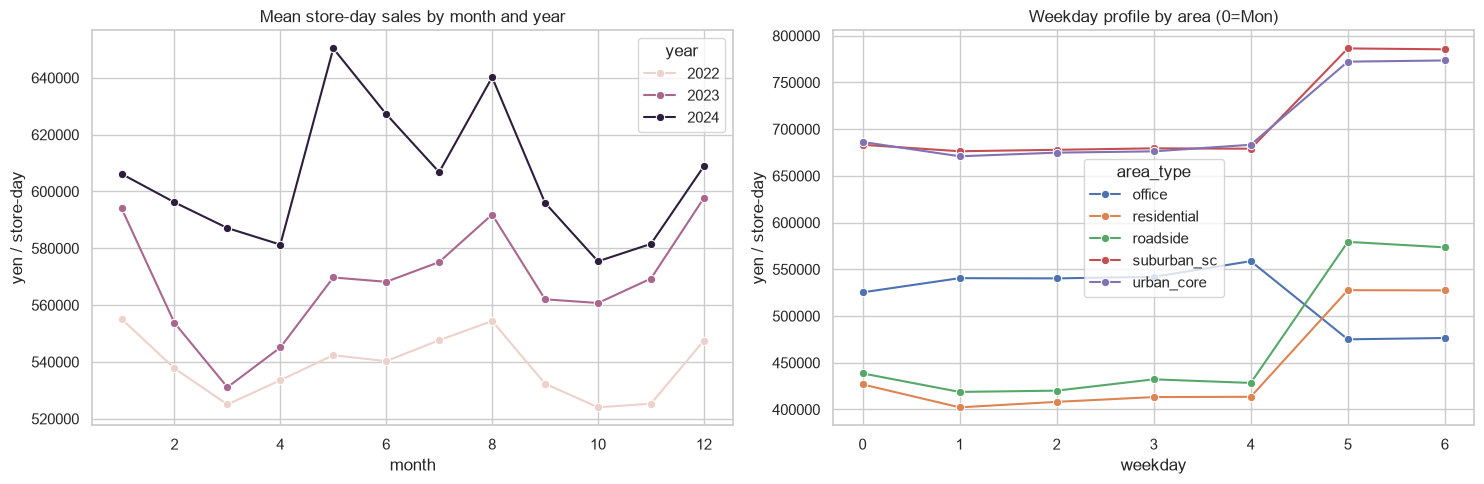

year,2022,2023,2024
area_type,,,
office,"514,955.268","522,614.518","530,148.239"
residential,"451,792.685","447,338.379","438,004.111"
roadside,"475,266.389","476,249.827","459,365.806"
suburban_sc,"643,233.316","690,686.523","795,293.622"
urban_core,"609,034.037","705,287.327","801,752.855"


In [5]:
store_daily=train.groupby(['date','store_id'],as_index=False).sales_amount.sum().merge(stores[['store_id','area_type']],on='store_id',validate='many_to_one')
store_daily['year']=store_daily.date.dt.year; store_daily['month']=store_daily.date.dt.month; store_daily['weekday']=store_daily.date.dt.dayofweek
display(store_daily.groupby(['year','store_id']).sales_amount.mean().unstack('year').assign(ratio_24_23=lambda d:d[2024]/d[2023]).sort_values('ratio_24_23'))
monthly=store_daily.groupby(['year','month'],as_index=False).sales_amount.mean()
fig,ax=plt.subplots(1,2,figsize=(15,5)); sns.lineplot(data=monthly,x='month',y='sales_amount',hue='year',marker='o',ax=ax[0]); ax[0].set(title='Mean store-day sales by month and year',ylabel='yen / store-day')
weekday=store_daily.groupby(['area_type','weekday'],as_index=False).sales_amount.mean(); sns.lineplot(data=weekday,x='weekday',y='sales_amount',hue='area_type',marker='o',ax=ax[1]); ax[1].set(title='Weekday profile by area (0=Mon)',ylabel='yen / store-day');plt.tight_layout();plt.show()
display(store_daily.groupby(['year','area_type']).sales_amount.mean().unstack('year'))

## 価格改定の予定と過去の同月比較
2024 年と 2025 年の同じ月日・店舗・商品を比較する。2024 年の 2 月 29 日は 2025 年に対応しない。これは計画価格の差であり、売上の価格弾力性を示さない。

Comparable price rows: 306600
fraction higher / same / lower: 0.8963 0.1037 0.0


,rows,mean,median,higher,lower
month,,,,,
1,26040,0.062,0.059,0.918,0.000
2,23520,0.062,0.059,0.918,0.000
3,26040,0.062,0.059,0.918,0.000
4,25200,0.037,0.034,0.889,0.000
5,26040,0.037,0.034,0.889,0.000
6,25200,0.037,0.034,0.889,0.000
7,26040,0.037,0.034,0.889,0.000
8,26040,0.037,0.034,0.889,0.000
9,25200,0.037,0.034,0.889,0.000


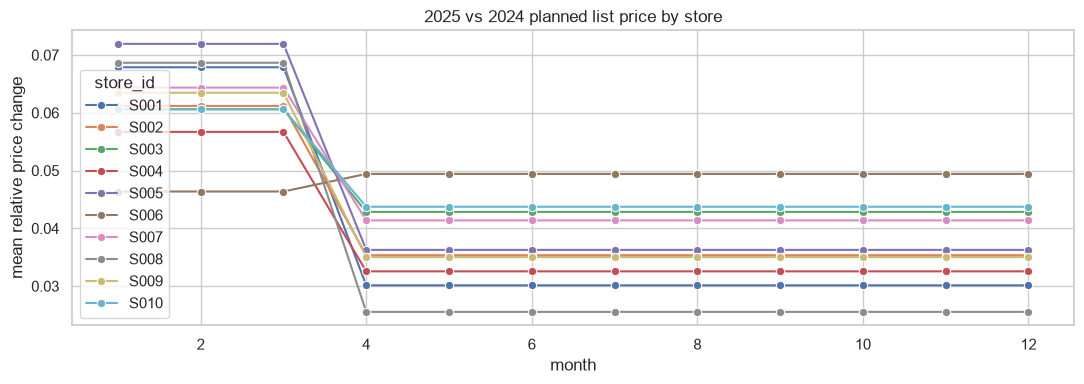

In [6]:
p=price_days[price_days.date.dt.year.isin([2024,2025])].copy(); p['year']=p.date.dt.year; p['month_day']=p.date.dt.month*100+p.date.dt.day
p24=p[p.year.eq(2024)&p.month_day.ne(229)][['month_day','store_id','item_id','selling_price']].rename(columns={'selling_price':'price_2024'})
p25=p[p.year.eq(2025)][['month_day','store_id','item_id','selling_price']].rename(columns={'selling_price':'price_2025'})
comparison=p24.merge(p25,on=['month_day','store_id','item_id'],validate='one_to_one'); comparison['pct_change']=comparison.price_2025/comparison.price_2024-1; comparison['month']=comparison.month_day // 100
print('Comparable price rows:',len(comparison)); print('fraction higher / same / lower:',*(round(x,4) for x in [(comparison['pct_change']>0).mean(),(comparison['pct_change']==0).mean(),(comparison['pct_change']<0).mean()]))
display(comparison.groupby('month')['pct_change'].agg(rows='size',mean='mean',median='median',higher=lambda x:(x>0).mean(),lower=lambda x:(x<0).mean()))
fig,ax=plt.subplots(figsize=(11,4));sns.lineplot(data=comparison.groupby(['month','store_id'],as_index=False)['pct_change'].mean(),x='month',y='pct_change',hue='store_id',marker='o',ax=ax);ax.set(title='2025 vs 2024 planned list price by store',ylabel='mean relative price change');plt.tight_layout();plt.show()

## 条件付きのキャンペーン比較
施策の対象店舗・商品カテゴリ・日を明示。曜日・季節・店舗等が異なり、以下の差を効果と断定できない。複数施策が重なる日もある。

In [7]:
discount_campaign=campaign_store[campaign_store.coupon_flag].copy()
# キャンペーンの対象商品群（main/lunch/kids/dessert）に一致する行だけを対象にする。
discount_keys=discount_campaign[['date','store_id','target_item_group']].rename(columns={'target_item_group':'category'}).drop_duplicates().assign(coupon_planned=True)
analysis=past.merge(discount_keys,on=['date','store_id','category'],how='left',validate='many_to_one')
analysis['coupon_planned']=analysis.coupon_planned.fillna(False).astype(bool); analysis['weekday']=analysis.date.dt.dayofweek; analysis['year']=analysis.date.dt.year
eligible_active=analysis[analysis.eligible & analysis.category.isin(['main','lunch','kids','dessert'])]
res=eligible_active.groupby(['category','weekday','coupon_planned'],observed=True).sales_amount.agg(rows='size',mean='mean',median='median',zero_fraction=lambda x:x.eq(0).mean())
display(res)
print('同一曜日内であっても店舗・季節・併催・対象商品構成が異なる。明細の値引きは施策予定とは別。')

同一曜日内であっても店舗・季節・併催・対象商品構成が異なる。明細の値引きは施策予定とは別。


rows       mean     median  zero_fraction
category weekday coupon_planned                                            
dessert  0       False           16912  2,071.064  1,680.000          0.042
                 True             3825  2,396.688  1,972.000          0.018
         1       False           16972  1,931.563  1,560.000          0.044
                 True             3764  2,373.479  1,975.000          0.019
         2       False           16660  1,934.519  1,560.000          0.047
                 True             3948  2,331.303  1,948.500          0.023
         3       False           16576  1,931.823  1,560.000          0.045
                 True             4046  2,403.878  1,990.000          0.017
         4       False           16380  1,990.954  1,640.000          0.043
                 True             4234  2,354.159  1,963.000          0.023
         5       False           16761  2,606.954  2,160.000          0.020
                 True             3969  3,115.687  2,625.000          0.012
         6       False           16929  2,609.568  2,160.000          0.023
                 True             3808  3,244.876  2,789.000          0.010
kids     0       False            9460  2,801.929  2,190.000          0.100
                 True              157  5,530.637  4,968.000          0.000
         1       False            9592  2,642.781  1,920.000          0.108
                 True               18  3,889.889  3,691.000          0.000
         2       False            9540  2,661.878  1,920.000          0.109
                 True               18  6,813.944  6,227.500          0.000
         3       False            9523  2,709.475  1,950.000          0.101
                 True               36  5,048.806  4,896.000          0.000
         4       False            9484  2,724.200  2,190.000          0.100
                 True               80  5,461.350  4,688.000          0.000
         5       False            8403  4,301.970  3,840.000          0.013
                 True             1207  5,331.694  4,896.000          0.007
         6       False            8406  4,260.350  3,840.000          0.014
                 True             1204  5,288.078  4,865.500          0.006
lunch    0       False           18132  4,732.070  4,500.000          0.014
                 True              708  7,316.407  7,116.000          0.000
         1       False           18144  4,778.600  4,500.000          0.014
                 True              696  7,157.261  7,062.000          0.001
         2       False           17688  4,719.411  4,450.000          0.013
                 True             1032  7,303.453  7,200.000          0.000
         3       False           18000  4,786.348  4,500.000          0.011
                 True              720  7,340.481  7,260.000          0.000
         4       False           17784  4,761.513  4,500.000          0.013
                 True              936  7,500.988  7,317.500          0.000
         5       False           18840  4,374.277  4,100.000          0.009
         6       False           18840  4,380.181  4,100.000          0.011
main     0       False           26670 19,380.209 17,850.000          0.000
                 True              347 25,325.305 23,316.000          0.000
         1       False           26965 19,150.823 17,800.000          0.000
                 True               51 22,836.216 20,868.000          0.000
         2       False           26780 19,241.784 17,800.000          0.000
                 True               68 23,097.765 21,604.000          0.000
         3       False           26759 19,387.208 18,000.000          0.000
                 True              103 23,234.583 22,470.000          0.000
         4       False           26769 19,522.672 18,190.000          0.000
                 True               85 21,607.624 19,788.000          0.000
         5       False           24340 21,761.430 20,020.000          0.000
      

## 使用上の注意
- 2025 年の売上、天候観測値、来店・注文ログは利用しない。平年値と事前配布された計画を使う。
- コラボ販売には期間と参加店舗の両方が必要。上の過去照合は配布データ上の整合性を示すが、実運用での例外を保証するものではない。
- 期間比較や施策の差は、客層・季節・店舗や他施策による交絡を含む。